# 3 — Preprocessing
Paper-guided benchmark: de Chazal et al., IEEE TBME 2004, DOI 10.1109/TBME.2004.827359.


## Configuration and common helpers


In [5]:
from pathlib import Path
import json, hashlib, random, time, copy, platform, importlib.metadata, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

VERSION_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / 'benchmark_config.json').is_file())
CONFIG = json.loads((VERSION_ROOT / 'benchmark_config.json').read_text(encoding='utf-8'))
RAW = Path(CONFIG['raw_directory'])
if not RAW.is_absolute():
    RAW = (VERSION_ROOT / RAW).resolve()
DATA = VERSION_ROOT / 'dataset/processed'
ARTIFACTS = VERSION_ROOT / 'model/artifacts'
REPORTS = VERSION_ROOT / 'model/reports'
CLASSES = CONFIG['classes']
N_CLASSES = len(CLASSES)
SEED = CONFIG['seed']
FS = 360
LEFT, RIGHT = CONFIG['left_samples'], CONFIG['right_samples']
WAVE_LENGTH = LEFT + RIGHT + 1
ALL_SYMBOLS = ['NLRej', 'AaJS', 'VE', 'F', '/fQ']
ALL_LABEL_MAP = {s: i for i, symbols in enumerate(ALL_SYMBOLS) for s in symbols}
if CLASSES != ['N', 'S', 'V', 'F'] or LEFT < 18 or RIGHT < 180 or not CONFIG['offline_context']:
    raise ValueError('This version requires N/S/V/F, at least 50 ms before / 500 ms after FP, and offline context')

def read_json(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'ไม่พบ {path}; รัน notebook ขั้นก่อนหน้าก่อน')
    return json.loads(path.read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def macro_f1(y, predicted):
    return float(f1_score(y, predicted, labels=list(range(N_CLASSES)), average='macro', zero_division=0))

def class_weights(y, power=0.5, cap=20.0):
    counts = np.bincount(np.asarray(y, dtype=int), minlength=N_CLASSES)
    if (counts == 0).any():
        raise ValueError('Training data must contain all configured classes')
    values = np.minimum((len(y) / (N_CLASSES * counts)) ** power, cap)
    return values / np.average(values, weights=counts)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
    except ImportError:
        pass

def environment():
    names = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'wfdb', 'pyarrow',
             'PyWavelets', 'xgboost', 'torch', 'optuna']
    versions = {}
    for name in names:
        try:
            versions[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            versions[name] = 'not installed'
    return {'python': platform.python_version(), 'platform': platform.platform(), 'packages': versions}

def validate_partitions(frame):
    if set(frame.split) != {'train', 'validation', 'test'}:
        raise ValueError('Require train, validation and test')
    if frame.beat_id.duplicated().any() or frame.groupby('patient_group').split.nunique().max() != 1:
        raise ValueError('Duplicate beat or patient leakage')
    for name, part in frame.groupby('split'):
        if set(part.class_id) != set(range(N_CLASSES)):
            raise ValueError(f'{name}: missing class')
    paired = frame.loc[frame.record_id.isin(['201', '202'])]
    if paired.patient_group.nunique() != 1 or paired.split.nunique() != 1:
        raise ValueError('201 and 202 must remain in one patient group and one partition')

def load_partition(split, *, allow_test=False):
    if split == 'test' and not allow_test:
        raise PermissionError('Test is evaluated only in notebook 9')
    manifest = read_json(DATA / 'prepared.json')
    if manifest['config_hash'] != sha256(VERSION_ROOT / 'benchmark_config.json'):
        raise ValueError('Configuration changed; rerun notebooks 1-4')
    for upstream in ['audit.json', 'split.json', 'preprocessing.json', 'feature_schema.json',
                     'inventory.parquet', 'split_inventory.parquet']:
        if sha256(DATA / upstream) != manifest['files'][upstream]:
            raise ValueError(f'Upstream artifact changed: {upstream}; rerun preparation')
    folder = DATA / split
    values = {}
    for key, name in [('meta', 'metadata.parquet'), ('wave', 'waveforms.npy'),
                      ('rr', 'rr.npy'), ('x', 'features_raw.npy')]:
        if sha256(folder / name) != manifest['files'][f'{split}/{name}']:
            raise ValueError(f'Artifact changed: {split}/{name}; rerun preparation')
        values[key] = pd.read_parquet(folder / name) if key == 'meta' else np.load(folder / name)
    m = values['meta']
    if not all(len(v) == len(m) for v in values.values()):
        raise ValueError('Array lengths differ')
    if not np.array_equal(m.waveform_index, np.arange(len(m))) or not m.split.eq(split).all():
        raise ValueError('Array/metadata alignment failed')
    if values['wave'].shape != (len(m), 2, WAVE_LENGTH) or not np.isfinite(values['wave']).all():
        raise ValueError('Invalid waveform shape or nonfinite waveform')
    values['y'] = m.class_id.to_numpy(dtype=np.int64)
    return values

def concatenate_partitions(parts):
    return {key: pd.concat([p[key] for p in parts], ignore_index=True) if key == 'meta'
            else np.concatenate([p[key] for p in parts]) for key in parts[0]}

def fit_transforms(part):
    feature_imputer = SimpleImputer(strategy='median', keep_empty_features=True)
    rr_imputer = SimpleImputer(strategy='median', keep_empty_features=True)
    rr_scaler = RobustScaler(quantile_range=(10., 90.))
    feature_imputer.fit(part['x'])
    rr_scaler.fit(rr_imputer.fit_transform(part['rr']))
    return {'feature_imputer': feature_imputer, 'rr_imputer': rr_imputer, 'rr_scaler': rr_scaler}

def transform_partition(part, transforms):
    result = dict(part)
    result['x'] = transforms['feature_imputer'].transform(part['x']).astype(np.float32)
    filled = transforms['rr_imputer'].transform(part['rr'])
    scaled = transforms['rr_scaler'].transform(filled)
    # Clipping bounds are fixed protocol constants; missing flags keep edge information.
    result['context'] = np.column_stack([np.clip(scaled, -10., 10.),
                                        ~np.isfinite(part['rr'])]).astype(np.float32)
    if not np.isfinite(result['x']).all() or not np.isfinite(result['context']).all():
        raise ValueError('Imputation/scaling produced nonfinite input')
    return result

def prepare_training(train_raw, validation_raw):
    transforms = fit_transforms(train_raw)
    return transform_partition(train_raw, transforms), transform_partition(validation_raw, transforms), transforms

def metrics(y, pred):
    report = classification_report(y, pred, labels=list(range(N_CLASSES)), target_names=CLASSES,
                                   output_dict=True, zero_division=0)
    matrix = confusion_matrix(y, pred, labels=list(range(N_CLASSES)))
    normalized = np.divide(matrix, matrix.sum(1, keepdims=True), out=np.zeros_like(matrix, dtype=float),
                           where=matrix.sum(1, keepdims=True) != 0)
    return {'accuracy': float(accuracy_score(y, pred)), 'macro_f1': macro_f1(y, pred),
            'weighted_f1': float(report['weighted avg']['f1-score']),
            'balanced_accuracy': float(normalized.diagonal().mean()), 'per_class': report,
            'confusion_matrix': matrix.tolist(), 'normalized_confusion_matrix': normalized.tolist()}

def plot_trials(study, destination):
    frame = study.trials_dataframe()
    frame.to_csv(destination / 'trials.csv', index=False)
    complete = frame.loc[frame.state.eq('COMPLETE')].copy()
    if len(complete):
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.plot(complete.number, complete.value, 'o-', alpha=.6, label='Validation Macro-F1')
        ax.plot(complete.number, complete.value.cummax(), linewidth=2, label='Best so far')
        ax.set(xlabel='Trial', ylabel='Macro-F1', ylim=(0, 1), title=study.study_name)
        ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
        fig.savefig(destination / 'tuning.png', dpi=160)
        plt.show(); plt.close(fig)


## Processing definitions


In [6]:
import wfdb
import pywt
from scipy.ndimage import median_filter
from scipy.signal import butter, sosfiltfilt
from scipy.stats import skew, kurtosis
from sklearn.model_selection import GroupShuffleSplit

def audit_dataset():
    records = (RAW / 'RECORDS').read_text().split()
    if len(records) != 48 or len(set(records)) != 48:
        raise ValueError('Expected the 48 primary MIT-BIH records')
    rows, excluded, files, record_info = [], [], {}, []
    for rid in records:
        for ext in ['hea', 'dat', 'atr']:
            files[f'{rid}.{ext}'] = sha256(RAW / f'{rid}.{ext}')
        if rid in CONFIG['excluded_records']:
            excluded.append({'record_id': rid, 'r_sample': None, 'symbol': None, 'reason': 'pacemaker_record'})
            continue
        header = wfdb.rdheader(str(RAW / rid))
        if header.fs != FS or 'MLII' not in header.sig_name:
            raise ValueError(f'{rid}: require 360 Hz and MLII; do not substitute another lead')
        ann = wfdb.rdann(str(RAW / rid), 'atr')
        patient = '201_202' if rid in ['201', '202'] else rid
        record_info.append({'record_id': rid, 'patient_group': patient, 'lead': 'MLII',
                            'lead_index': header.sig_name.index('MLII'), 'samples': header.sig_len})
        for sample, symbol in zip(ann.sample, ann.symbol):
            label = ALL_LABEL_MAP.get(symbol)
            if label is None or label >= N_CLASSES:
                excluded.append({'record_id': rid, 'r_sample': int(sample), 'symbol': symbol,
                                 'reason': 'Q_outside_four_class_task' if label == 4 else 'non_beat_annotation'})
                continue
            if not 0 <= sample < header.sig_len:
                raise ValueError(f'{rid}: annotation out of range')
            rows.append({'beat_id': f'{rid}:{sample}', 'record_id': rid, 'patient_group': patient,
                         'r_sample': int(sample), 'original_symbol': symbol, 'class_id': label, 'lead': 'MLII'})
    frame = pd.DataFrame(rows)
    if frame.beat_id.duplicated().any():
        raise ValueError('Duplicate beat IDs')
    return frame, pd.DataFrame(excluded), {'records': record_info, 'raw_files': files,
        'reference_doi': CONFIG['reference_doi'], 'protocol': CONFIG['protocol'],
        'config_hash': sha256(VERSION_ROOT / 'benchmark_config.json')}

def split_patients(frame, candidates=5000):
    # DS2 is fixed from the reference protocol, with 202 moved to development to keep 201/202 together.
    test_records = set(CONFIG['test_records'])
    dev = frame.loc[~frame.record_id.isin(test_records)].reset_index(drop=True)
    target = CONFIG['validation_fraction_of_development']
    minimum_train = np.array([1000, 100, 100, 100])
    minimum_val = np.array([500, 40, 100, 10])
    best = None
    splitter = GroupShuffleSplit(n_splits=candidates, test_size=target, random_state=SEED)
    for trial_number, (tr, va) in enumerate(splitter.split(dev, dev.class_id, dev.patient_group)):
        train_counts = np.bincount(dev.iloc[tr].class_id, minlength=N_CLASSES)
        val_counts = np.bincount(dev.iloc[va].class_id, minlength=N_CLASSES)
        if (train_counts < minimum_train).any() or (val_counts < minimum_val).any():
            continue
        allocation_error = float(np.abs(val_counts / (train_counts + val_counts) - target).mean())
        key = (allocation_error, trial_number)
        if best is None or key < best[0]:
            best = (key, set(dev.iloc[va].patient_group))
    if best is None:
        raise ValueError('No feasible grouped validation split; review constraints without using model scores')
    result = frame.copy()
    result['split'] = 'train'
    result.loc[result.patient_group.isin(best[1]), 'split'] = 'validation'
    result.loc[result.record_id.isin(test_records), 'split'] = 'test'
    validate_partitions(result)
    info = {'record_split': result.groupby('record_id').split.first().to_dict(),
            'patient_split': result.groupby('patient_group').split.first().to_dict(),
            'test_rule': 'de Chazal DS2 minus 202; 201 and 202 both development',
            'validation_rule': 'label-count stratification within development only; no model scores',
            'validation_allocation_error': best[0][0], 'seed': SEED,
            'minimum_train': minimum_train.tolist(), 'minimum_validation': minimum_val.tolist()}
    return result, info

def filter_ecg(signal):
    signal = np.asarray(signal, dtype=np.float64)
    if not np.isfinite(signal).all():
        raise ValueError('ECG contains NaN/Inf')
    # de Chazal: consecutive 200 ms / 600 ms median filters for baseline removal.
    # Adaptation: zero-phase Butterworth low-pass 35 Hz replaces the paper's 12-tap FIR.
    baseline = median_filter(median_filter(signal, size=73, mode='nearest'), size=217, mode='nearest')
    sos = butter(4, 35., btype='lowpass', fs=FS, output='sos')
    return sosfiltfilt(sos, signal - baseline)

RR_NAMES = ['rr_pre', 'rr_post', 'rr_global_mean', 'rr_local_mean', 'rr_pre_local',
            'rr_post_local', 'rr_pre_global', 'rr_post_global', 'rr_pre_post_ratio',
            'rr_delta_local', 'rr_local_std', 'rr_local_cv']

def rr_features(samples):
    samples = np.asarray(samples, dtype=np.int64)
    if len(samples) < 2 or (np.diff(samples) <= 0).any():
        raise ValueError('Need at least two strictly ordered beat positions')
    intervals = np.diff(samples) / FS
    pre, post = np.r_[np.nan, intervals], np.r_[intervals, np.nan]
    series = pd.Series(pre)
    local = series.rolling(10, center=True, min_periods=1).mean().to_numpy()
    local_std = series.rolling(10, center=True, min_periods=2).std(ddof=0).to_numpy()
    global_mean = np.full(len(samples), intervals.mean())
    return np.column_stack([pre, post, global_mean, local, pre/local, post/local,
                            pre/global_mean, post/global_mean, pre/post,
                            (post-pre)/local, local_std, local_std/local])

def segment_record(record_id, part):
    record = wfdb.rdrecord(str(RAW / record_id))
    if record.fs != FS:
        raise ValueError('Unexpected sampling rate')
    signal = record.p_signal[:, record.sig_name.index('MLII')]
    filtered = filter_ecg(signal)
    record_scale = max(float(filtered.std()), 1e-6)
    ann = wfdb.rdann(str(RAW / record_id), 'atr')
    # Include Q beats in RR timing even though they are excluded as classification targets.
    positions = np.array([s for s, symbol in zip(ann.sample, ann.symbol) if symbol in ALL_LABEL_MAP])
    contexts = rr_features(positions)
    lookup = {int(s): i for i, s in enumerate(positions)}
    part = part.sort_values('r_sample').copy()
    valid = (part.r_sample >= LEFT) & (part.r_sample + RIGHT < len(signal))
    dropped = part.loc[~valid, ['beat_id', 'record_id']].assign(reason='window_boundary')
    meta = part.loc[valid].copy()
    windows = np.array([filtered[int(r)-LEFT:int(r)+RIGHT+1] for r in meta.r_sample], dtype=np.float32)
    record_normalized = windows / record_scale
    beat_std = np.maximum(windows.std(axis=1, keepdims=True), 1e-6)
    beat_normalized = (windows - windows.mean(axis=1, keepdims=True)) / beat_std
    waves = np.stack([record_normalized, beat_normalized], axis=1).astype(np.float32)
    rr = np.array([contexts[lookup[int(r)]] for r in meta.r_sample], dtype=np.float64)
    return meta, waves, rr, dropped

def extract_features(waves, rr):
    raw, normalized = waves[:, 0], waves[:, 1]
    # Fixed-interval morphology follows the paper's FP-centered QRS/T sampling idea.
    morphology_offsets = np.r_[np.linspace(-.05, .10, 10), np.linspace(.15, .50, 8)] * FS + LEFT
    full_offsets = np.linspace(0, WAVE_LENGTH-1, 64)
    morphology = np.vstack([np.interp(morphology_offsets, np.arange(WAVE_LENGTH), w) for w in raw])
    morphology_norm = np.vstack([np.interp(morphology_offsets, np.arange(WAVE_LENGTH), w) for w in normalized])
    shape = np.vstack([np.interp(full_offsets, np.arange(WAVE_LENGTH), w) for w in normalized])
    delta = np.diff(raw, axis=1)
    stats = np.column_stack([raw.mean(1), raw.std(1), raw.min(1), raw.max(1), np.median(raw, axis=1),
        np.ptp(raw, axis=1), np.sqrt((raw**2).mean(1)), (raw**2).sum(1),
        skew(raw, axis=1), kurtosis(raw, axis=1), delta.std(1), delta.min(1), delta.max(1)])
    packets = []
    for w in raw:
        nodes = pywt.WaveletPacket(w, 'db4', mode='symmetric', maxlevel=4).get_level(4, order='freq')
        energy = np.array([np.square(node.data).sum() for node in nodes])
        relative = energy / max(energy.sum(), 1e-12)
        entropy = []
        for node in nodes:
            e = np.square(node.data); p = e / max(e.sum(), 1e-12)
            entropy.append(float(-np.sum(p * np.log(p + 1e-12))))
        packets.append(np.r_[relative, entropy])
    names = RR_NAMES + [n+'_missing' for n in RR_NAMES]
    names += [f'paper_morphology_{i:02d}' for i in range(18)]
    names += [f'normalized_morphology_{i:02d}' for i in range(18)]
    names += [f'normalized_shape_{i:02d}' for i in range(64)]
    names += ['mean','std','min','max','median','peak_to_peak','rms','energy','skew','kurtosis',
              'diff_std','diff_min','diff_max']
    names += [f'packet_relative_energy_{i:02d}' for i in range(16)]
    names += [f'packet_entropy_{i:02d}' for i in range(16)]
    values = np.column_stack([rr, ~np.isfinite(rr), morphology, morphology_norm, shape, stats, packets])
    values[~np.isfinite(values)] = np.nan
    return values.astype(np.float32), names


## Verify raw inputs


In [7]:
audit=read_json(DATA/'audit.json'); split=read_json(DATA/'split.json')
if sha256(DATA/'audit.json')!=split['audit_hash'] or audit['config_hash']!=sha256(VERSION_ROOT/'benchmark_config.json'):
    raise ValueError('Input configuration changed; rerun notebooks 1-2')
for name,expected in audit['raw_files'].items():
    if sha256(RAW/name)!=expected: raise ValueError(f'Raw file changed: {name}')
inventory=pd.read_parquet(DATA/'split_inventory.parquet')
validate_partitions(inventory)


## Filter, segment and extract RR before target exclusions


In [8]:
metadata=[]; waveform_chunks=[]; rr_chunks=[]; dropped=[]
for number,(rid,part) in enumerate(inventory.groupby('record_id',sort=True),1):
    meta,wave,rr,excluded=segment_record(rid,part)
    metadata.append(meta); waveform_chunks.append(wave); rr_chunks.append(rr); dropped.append(excluded)
    print(f'{number}/44 record {rid}: {len(meta):,} beats')
meta=pd.concat(metadata,ignore_index=True)
waves=np.concatenate(waveform_chunks); rr=np.concatenate(rr_chunks)
validate_partitions(meta)
for name in ['train','validation','test']:
    mask=meta.split.eq(name).to_numpy(); folder=DATA/name; folder.mkdir(parents=True,exist_ok=True)
    selected=meta.loc[mask].reset_index(drop=True); selected['waveform_index']=np.arange(len(selected))
    selected.to_parquet(folder/'metadata.parquet',index=False)
    np.save(folder/'waveforms.npy',waves[mask]); np.save(folder/'rr.npy',rr[mask])
pd.concat(dropped,ignore_index=True).to_csv(DATA/'boundary_exclusions.csv',index=False)
write_json(DATA/'preprocessing.json',{'config_hash':sha256(VERSION_ROOT/'benchmark_config.json'),
    'split_hash':sha256(DATA/'split.json'),'classes':CLASSES,'shape':[2,WAVE_LENGTH],
    'rr_names':RR_NAMES,'resampling':False,'offline':True,
    'normalization':'unlabelled within-record std and within-beat z-score; no population scaler'})
display(pd.crosstab(meta.split,meta.class_id).rename(columns=dict(enumerate(CLASSES))))


1/44 record 100: 2,271 beats
2/44 record 101: 1,862 beats
3/44 record 103: 2,083 beats
4/44 record 105: 2,567 beats
5/44 record 106: 2,027 beats
6/44 record 108: 1,762 beats
7/44 record 109: 2,531 beats
8/44 record 111: 2,124 beats
9/44 record 112: 2,538 beats
10/44 record 113: 1,794 beats
11/44 record 114: 1,879 beats
12/44 record 115: 1,952 beats
13/44 record 116: 2,411 beats
14/44 record 117: 1,534 beats
15/44 record 118: 2,277 beats
16/44 record 119: 1,987 beats
17/44 record 121: 1,862 beats
18/44 record 122: 2,475 beats
19/44 record 123: 1,517 beats
20/44 record 124: 1,618 beats
21/44 record 200: 2,600 beats
22/44 record 201: 1,963 beats
23/44 record 202: 2,135 beats
24/44 record 203: 2,976 beats
25/44 record 205: 2,655 beats
26/44 record 207: 1,859 beats
27/44 record 208: 2,951 beats
28/44 record 209: 3,004 beats
29/44 record 210: 2,648 beats
30/44 record 212: 2,747 beats
31/44 record 213: 3,250 beats
32/44 record 214: 2,258 beats
33/44 record 215: 3,362 beats
34/44 record 219: 2

class_id,N,S,V,F
split,,,,
test,42180,1782,3201,387
train,37980,804,3010,386
validation,9928,195,797,29


## Distributions after preprocessing
Run the preprocessing cell above first. These plots use retained beats (`meta`) and follow notebook 2: split totals include unique patients; class percentages are within each split.


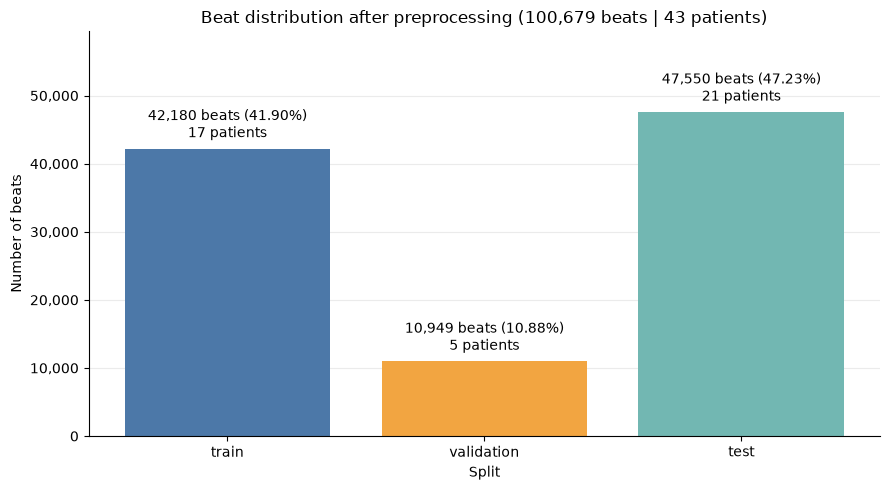

In [9]:
split_order = ['train', 'validation', 'test']
split_counts = meta['split'].value_counts().reindex(split_order, fill_value=0)
split_patient_counts = (meta.groupby('split')['patient_group'].nunique()
                        .reindex(split_order, fill_value=0))
total_patients = int(meta['patient_group'].nunique())
total_beats = int(split_counts.sum())
split_percentages = split_counts / total_beats * 100 if total_beats else split_counts.astype(float)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(split_order, split_counts.to_numpy(), color=['#4C78A8', '#F2A541', '#72B7B2'])
ax.bar_label(bars, labels=[f'{count:,} beats ({percentage:.2f}%)\n{patients:,} patients'
                           for count, percentage, patients in zip(split_counts, split_percentages, split_patient_counts)], padding=5)
ax.set(xlabel='Split', ylabel='Number of beats',
       title=f'Beat distribution after preprocessing ({total_beats:,} beats | {total_patients:,} patients)',
       ylim=(0, max(int(split_counts.max()), 1) * 1.25))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()
plt.close(fig)


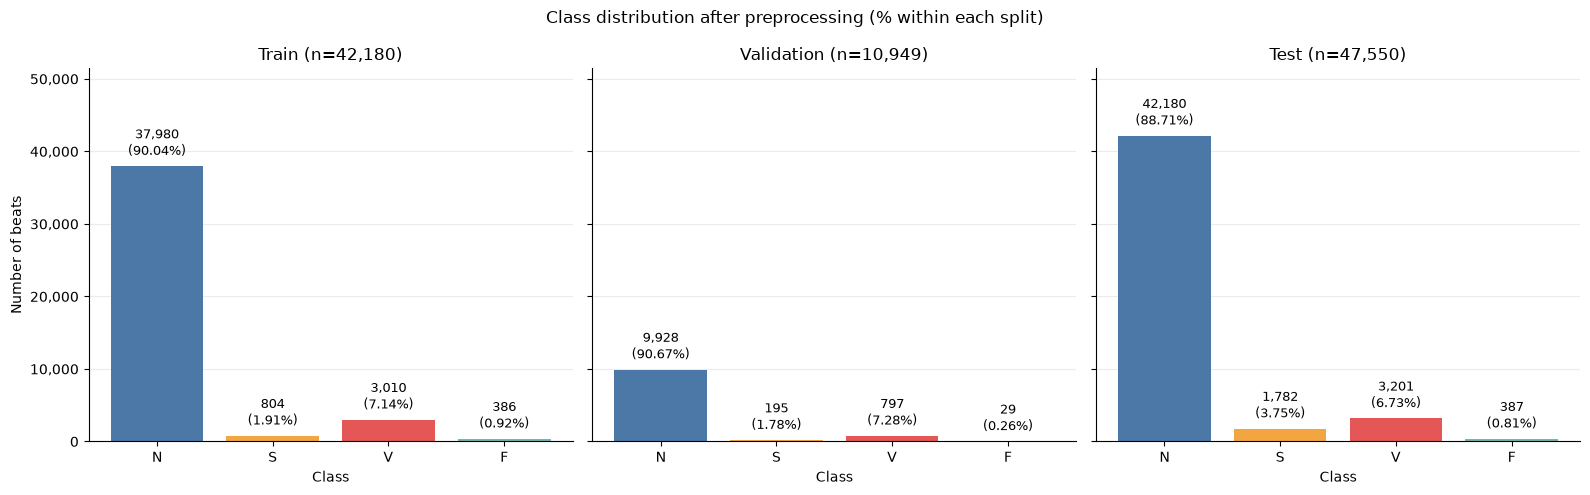

In [10]:
split_class_counts = pd.crosstab(meta['split'], meta['class_id']).reindex(
    index=['train', 'validation', 'test'], columns=range(N_CLASSES), fill_value=0)
split_class_counts.columns = CLASSES
class_colors = ['#4C78A8', '#F2A541', '#E45756', '#72B7B2']

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
upper_limit = max(int(split_class_counts.to_numpy().max()), 1) * 1.22
for ax, (split_name, counts) in zip(axes, split_class_counts.iterrows()):
    split_total = int(counts.sum())
    percentages = counts / split_total * 100 if split_total else counts.astype(float)
    bars = ax.bar(CLASSES, counts.to_numpy(), color=class_colors)
    ax.bar_label(bars, labels=[f'{count:,}\n({percentage:.2f}%)'
                               for count, percentage in zip(counts, percentages)],
                 padding=5, fontsize=9)
    ax.set(xlabel='Class', title=f'{split_name.title()} (n={split_total:,})', ylim=(0, upper_limit))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Number of beats')
fig.suptitle('Class distribution after preprocessing (% within each split)')
fig.tight_layout()
plt.show()
plt.close(fig)


## Before / after preprocessing
Compare the split inventory before preprocessing with retained metadata afterward. `removed` is before minus after. Class counts below are beats; patient counts are unique within each split.


In [11]:
comparison_splits = ['train', 'validation', 'test']
def preprocessing_count_summary(frame):
    totals = frame.groupby('split').agg(
        beats=('beat_id', 'size'), patients=('patient_group', 'nunique'))
    totals = totals.reindex(comparison_splits, fill_value=0)
    classes = pd.crosstab(frame['split'], frame['class_id']).reindex(
        index=comparison_splits, columns=range(N_CLASSES), fill_value=0)
    classes.columns = CLASSES
    return totals.join(classes).astype(int)

before_counts = preprocessing_count_summary(inventory)
after_counts = preprocessing_count_summary(meta)
count_comparison = pd.concat(
    {'before': before_counts, 'after': after_counts, 'removed': before_counts - after_counts}, axis=1)
count_comparison = count_comparison.swaplevel(0, 1, axis=1).reindex(
    columns=pd.MultiIndex.from_product([before_counts.columns, ['before', 'after', 'removed']]))
display(count_comparison)
print(f'Beats removed during preprocessing: {len(inventory) - len(meta):,}')


beats                patients                    N                 \
           before  after removed   before after removed before  after removed   
split                                                                           
train       42196  42180      16       17    17       0  37995  37980      15   
validation  10953  10949       4        5     5       0   9932   9928       4   
test        47569  47550      19       21    21       0  42198  42180      18   

                S                    V                    F                
           before after removed before after removed before after removed  
split                                                                      
train         804   804       0   3010  3010       0    387   386       1  
validation    195   195       0    797   797       0     29    29       0  
test         1782  1782       0   3202  3201       1    387   387       0

Beats removed during preprocessing: 39
